In [1]:
from functools import partial


import matplotlib.pyplot as plt
import jax.numpy as jnp
import flax.linen as nn
import seaborn as sns
import numpy as np
import optax
import jax
from flax.training.train_state import TrainState
from jax import jit, random, value_and_grad, vmap
from sklearn.metrics import confusion_matrix
from tqdm import tqdm

If you get this error in Google Colab

```python
/usr/local/lib/python3.13/dist-packages/jax/_src/deprecations.py in getattr(name)
     52       message, fn = deprecations[name]
     53       if fn is None:  # Is the deprecation accelerated?
---> 54         raise AttributeError(message)
     55       warnings.warn(message, DeprecationWarning, stacklevel=2)
     56       return fn

AttributeError: jax.core.get_opaque_trace_state was deprecated in JAX v0.10.0 and removed in JAX v0.11.0.  Use jax.extend.core.get_opaque_trace_state.
```

Try running this and it should be fixed

```python
!pip install --upgrade -q flax

import flax
import jax
if not hasattr(jax.core, 'get_opaque_trace_state'):
    import jax.extend.core
    jax.core.get_opaque_trace_state = jax.extend.core.get_opaque_trace_state
```

In [2]:
class DataLoader:
    def __init__(self, X, y, batch_size, key=random.PRNGKey(0)):
        self.X = X
        self.y = y
        self.N = X.shape[0]
        self.batch_size = batch_size
        self.key = key

    def __iter__(self):
        return self

    def __next__(self):
        self.key, subkey = random.split(self.key)
        idx = random.choice(subkey, self.N, (self.batch_size,), replace=False)
        return self.X[idx], self.y[idx]

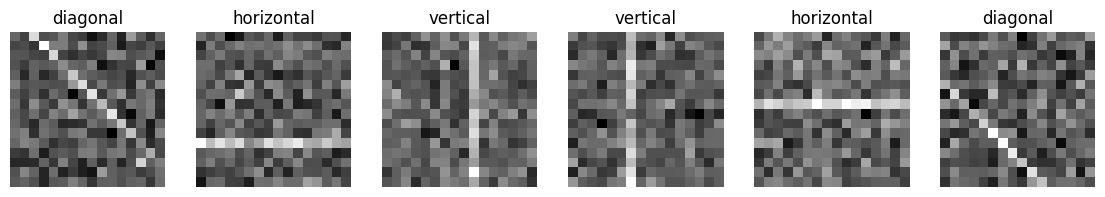

In [3]:
def make_images(key, n, size=16):
    k1, k2, k3 = random.split(key, 3)
    targets = random.randint(k1, (n,), 0, 3)
    pos = random.randint(k2, (n,), 2, size - 2)

    idx = jnp.arange(size)
    rows = idx[None, :, None] == pos[:, None, None]
    cols = idx[None, None, :] == pos[:, None, None]
    diag = (idx[None, :, None] - idx[None, None, :]) == (pos[:, None, None] - size // 2)

    horizontal = rows * jnp.ones((1, 1, size))
    vertical = cols * jnp.ones((1, size, 1))
    images = jnp.where(targets[:, None, None] == 0, horizontal, jnp.where(targets[:, None, None] == 1, vertical, diag))

    images = images + 0.3 * random.normal(k3, images.shape)
    return images[..., None], targets

class_names = ["horizontal", "vertical", "diagonal"]

train_images, train_targets = make_images(random.PRNGKey(1), 3000)
test_images, test_targets = make_images(random.PRNGKey(2), 600)

train_labels = jax.nn.one_hot(train_targets, 3)

fig, ax = plt.subplots(nrows=1, ncols=6, figsize=(14, 3))
for i, axx in enumerate(ax):
    axx.imshow(train_images[i, :, :, 0], cmap="gray")
    axx.set_title(class_names[int(train_targets[i])])
    axx.axis("off")
plt.show()

In [4]:
class MLP(nn.Module):
    hidden_dim: int
    num_layers: int
    num_classes: int

    @nn.compact
    def __call__(self, x):
        x = x.reshape(-1)

        for _ in range(self.num_layers):
            x = nn.Dense(self.hidden_dim)(x)
            x = nn.relu(x)

        x = nn.Dense(self.num_classes)(x)
        return x

In [5]:
class Classifier:
    def __init__(self, arch):
        dummy = jnp.ones((16, 16, 1))
        params = arch.init(random.PRNGKey(0), x=dummy)

        lr = optax.warmup_exponential_decay_schedule(
            init_value=1e-08,
            peak_value=1e-03,
            warmup_steps=200,
            transition_steps=500,
            decay_rate=0.9
        )

        tx = optax.adam(lr)

        self.state = TrainState.create(
            apply_fn=arch.apply,
            params=params,
            tx=tx
        )

        self.forward = vmap(self.state.apply_fn, (None, 0))

    @partial(jit, static_argnums=(0,))
    def predict(self, state, images):
        logits = self.forward(state.params, images)
        return jnp.argmax(logits, axis=-1)

    def loss(self, params, batch):
        images, labels = batch
        logits = self.forward(params, images)
        return optax.softmax_cross_entropy(logits, labels).mean()

    @partial(jit, static_argnums=(0,))
    def step(self, state, batch):
        loss, grads = value_and_grad(self.loss)(state.params, batch)
        state = state.apply_gradients(grads=grads)
        return state, loss

In [6]:
model = Classifier(MLP(hidden_dim=64, num_layers=2, num_classes=3))

steps = 2000
losses = []

train_data = DataLoader(train_images, train_labels, batch_size=64)

for _ in tqdm(range(steps)):
    batch = next(train_data)
    model.state, loss = model.step(model.state, batch)
    losses.append(loss)

100%|██████████| 2000/2000 [00:11<00:00, 167.64it/s]


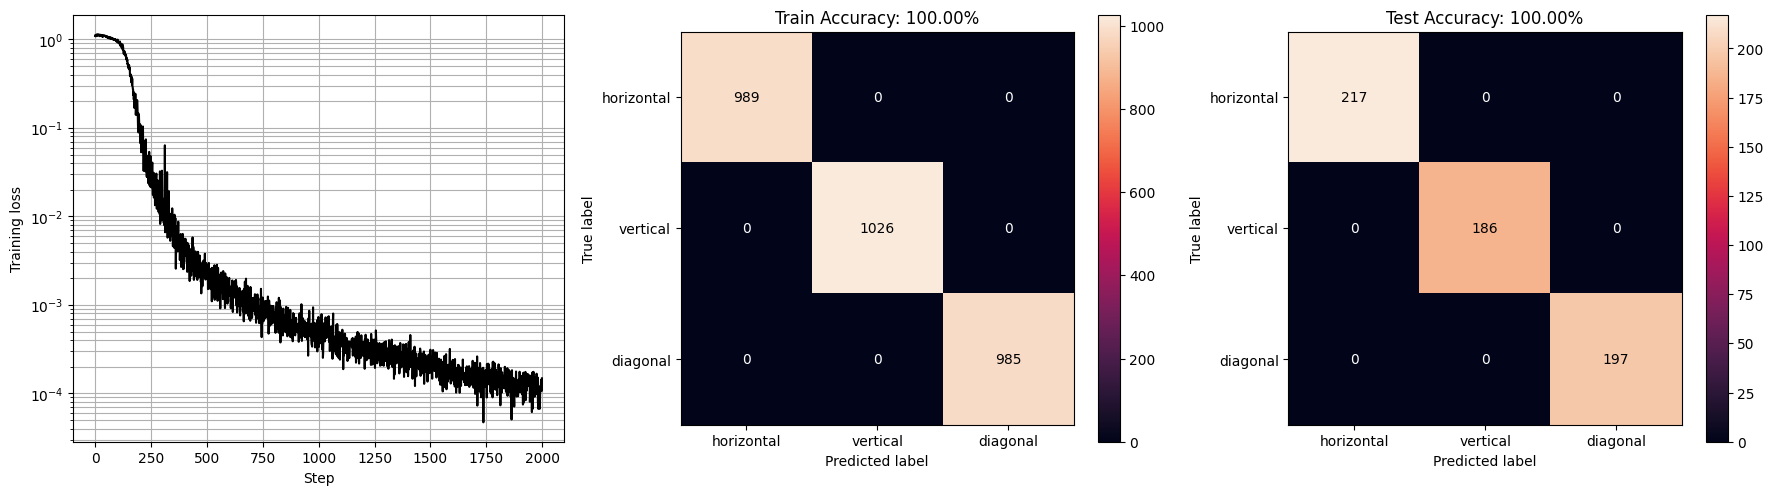

In [7]:
train_pred = model.predict(model.state, train_images)
test_pred = model.predict(model.state, test_images)

train_cm = confusion_matrix(train_targets, train_pred)
test_cm = confusion_matrix(test_targets, test_pred)

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

axx = ax[0]
axx.plot(losses, c="k")
axx.set_yscale("log")
axx.set_xlabel("Step")
axx.set_ylabel("Training loss")
axx.grid(which="both")

for axx, cm, title in zip(ax[1:], [train_cm, test_cm], ["Train", "Test"]):
    im = axx.imshow(cm, cmap="rocket")
    fig.colorbar(im, ax=axx)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = "black" if cm[i, j] > cm.max() / 2 else "white"
            axx.text(j, i, cm[i, j], ha="center", va="center", color=color)
    axx.set_xticks(range(3), class_names)
    axx.set_yticks(range(3), class_names)
    axx.set_xlabel("Predicted label")
    axx.set_ylabel("True label")
    axx.set_title(f"{title} Accuracy: {100.0 * np.trace(cm) / np.sum(cm):.2f}%")

plt.tight_layout()
plt.show()